# CS771 (2026-2027, Sem-I)
# Lecture 11 Companion Notebook
# Basics of Probabilistic Machine Learning

This notebook follows **Lecture 11 only**. Topics covered include:

**why probabilistic modeling → Bernoulli observations → population probability vs sample fraction → probability vs likelihood → MLE and NLL → MLE overconfidence → regularization → priors → posterior distributions → MAP → Beta prior and Bernoulli MAP**.

The recurring example is the manufacturing-plant problem. For an inspected item,

$$
y=\begin{cases}
1,&\text{item is functioning},\\
0,&\text{item is defective},
\end{cases}
$$

and $\theta\in[0,1]$ denotes the population probability that a randomly inspected item is functioning.

## 1. Setup

We use NumPy, Pandas, Matplotlib, and a few routines from SciPy. The examples are intentionally small so that likelihoods, priors, and point estimates remain easy to inspect.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import beta
from IPython.display import display

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

plt.rcParams['figure.figsize'] = (7, 5)
plt.rcParams['axes.grid'] = True

## 2. Why probabilistic modeling?

A deterministic predictor returns a single value,

$$
\hat y=f(\mathbf x;\boldsymbol\theta),
$$

whereas a probabilistic model describes possible outcomes through a distribution such as

$$
p(y\mid \mathbf x,\boldsymbol\theta).
$$

This gives us a language for **probabilistic predictions**, **uncertainty**, assumptions about data and parameters, and generation of new samples.

For Lecture 11 we begin with the simplest setting: no input features $\mathbf x$, only binary inspection outcomes.

In [ ]:
theta = 0.8
samples = rng.binomial(1, theta, size=20)

print("Model says P(functioning) =", theta)
print("20 possible inspection outcomes:")
print(samples)
print("Observed fraction functioning =", samples.mean())

Model says P(functioning) = 0.8
20 possible inspection outcomes:
[1 1 0 1 1 0 1 1 1 1 1 0 1 0 1 1 1 1 0 1]
Observed fraction functioning = 0.75


## 3. A simple probabilistic learning problem

Suppose a manufacturing plant produces items and we inspect whether each item functions.

We want to estimate an unknown parameter

$$
\theta=P(y=1),\qquad 1-\theta=P(y=0).
$$

The dataset is

$$
\mathcal D=\{y_1,\ldots,y_N\},\qquad y_n\in\{0,1\}.
$$

The same setup appears in heads vs tails, click vs no-click, component failure vs no failure, and positive vs negative labels.

## 4. Bernoulli model for binary observations

A binary observation is naturally modeled as

$$
y_n\mid\theta\sim\operatorname{Bernoulli}(\theta),
$$

with PMF

$$
p(y_n\mid\theta)=\theta^{y_n}(1-\theta)^{1-y_n}.
$$

Thus

$$
p(y_n=1\mid\theta)=\theta,\qquad p(y_n=0\mid\theta)=1-\theta.
$$

We assume that conditioned on $\theta$, the observations are i.i.d.

### 4.1 Population probability versus observed fraction

The true $\theta$ belongs to the data-generating process. The finite-sample fraction

$$
\hat\theta=\frac{N_1}{N},
\qquad
N_1=\sum_{n=1}^N y_n,
$$

belongs to the particular dataset we happened to observe. They need not be equal.

In [ ]:
true_theta = 0.7
sample_sizes = [5, 20, 100, 5000]

rows = []
for N in sample_sizes:
    D = rng.binomial(1, true_theta, size=N)
    rows.append([N, int(D.sum()), D.mean()])

display(pd.DataFrame(
    rows,
    columns=["N", "N1 (successes)", "observed fraction N1/N"]
))

,N,N1 (successes),observed fraction N1/N
0,5,1,0.2000
1,20,15,0.7500
2,100,78,0.7800
3,5000,3531,0.7062


## 5. Probability versus likelihood

The expression $p(y_n\mid\theta)$ can be viewed in two different ways.

- **Probability:** fix $\theta$ and vary the possible observation $y_n$.
- **Likelihood:** fix the observed $y_n$ and vary $\theta$.

For an i.i.d. dataset with $N_1$ successes and $N_0=N-N_1$ failures,

$$
L(\theta;\mathcal D)=p(\mathcal D\mid\theta)
=\theta^{N_1}(1-\theta)^{N_0}.
$$

Likelihood is a function of the parameter for a fixed observed dataset; it is not itself a probability distribution over $\theta$.

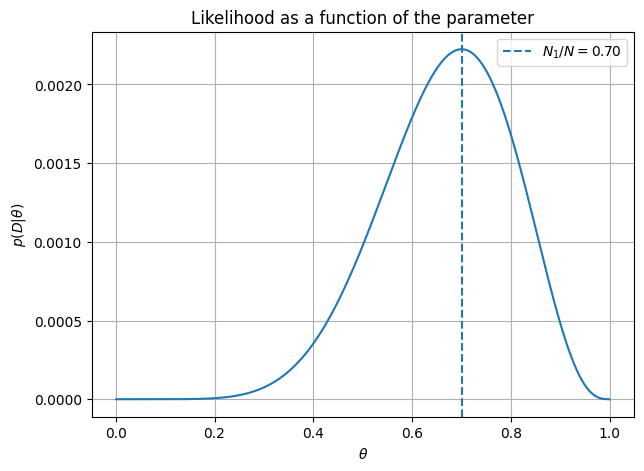

In [ ]:
D = np.array([1, 1, 1, 0, 1, 0, 1, 1, 1, 0])
N = len(D)
N1 = int(D.sum())
N0 = N - N1

theta_grid = np.linspace(0.001, 0.999, 1000)
likelihood = theta_grid**N1 * (1 - theta_grid)**N0

plt.plot(theta_grid, likelihood)
plt.axvline(N1/N, linestyle='--', label=fr'$N_1/N={N1/N:.2f}$')
plt.xlabel(r'$\theta$')
plt.ylabel(r'$p(D |	\theta)$')
plt.title('Likelihood as a function of the parameter')
plt.legend()
plt.show()

## 6. Maximum likelihood estimation and negative log-likelihood

Maximum likelihood chooses the parameter value that makes the observed data most likely:

$$
\hat\theta_{\mathrm{MLE}}
=\arg\max_\theta p(\mathcal D\mid\theta)
=\arg\max_\theta \log p(\mathcal D\mid\theta)
=\arg\min_\theta[-\log p(\mathcal D\mid\theta)].
$$

For i.i.d. observations,

$$
\log p(\mathcal D\mid\theta)
=\sum_{n=1}^N \log p(y_n\mid\theta).
$$

So the **negative log-likelihood (NLL)** behaves like a loss function. Taking logs also avoids numerical underflow caused by multiplying many small probabilities.

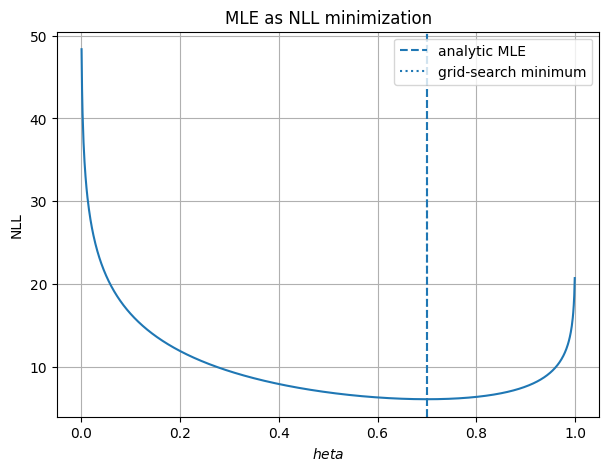

Analytic MLE: 0.7
Grid-search approximation: 0.7002992992992993


In [ ]:
eps = 1e-12

def bernoulli_nll(theta, N1, N0):
    theta = np.clip(theta, eps, 1-eps)
    return -(N1*np.log(theta) + N0*np.log(1-theta))

nll = bernoulli_nll(theta_grid, N1, N0)
theta_grid_mle = theta_grid[np.argmin(nll)]

plt.plot(theta_grid, nll)
plt.axvline(N1/N, linestyle='--', label='analytic MLE')
plt.axvline(theta_grid_mle, linestyle=':', label='grid-search minimum')
plt.xlabel(r'$	heta$')
plt.ylabel('NLL')
plt.title('MLE as NLL minimization')
plt.legend()
plt.show()

print("Analytic MLE:", N1/N)
print("Grid-search approximation:", theta_grid_mle)

## 7. MLE for the Bernoulli model

For Bernoulli data,

$$
\log p(\mathcal D\mid\theta)
=N_1\log\theta+N_0\log(1-\theta).
$$

Differentiating and setting the derivative to zero gives

$$
\boxed{\hat\theta_{\mathrm{MLE}}=\frac{N_1}{N}.}
$$

So the MLE is simply the observed fraction of successes.

In [ ]:
examples = [
    np.array([1, 0, 1, 1, 0]),
    np.array([1, 1, 1, 1, 1]),
    np.array([0, 0, 0, 0, 0]),
]

rows = []
for D in examples:
    N = len(D)
    N1 = int(D.sum())
    rows.append([D.tolist(), N1, N, N1/N])

display(pd.DataFrame(rows, columns=["dataset", "N1", "N", "Bernoulli MLE"]))

,dataset,N1,N,Bernoulli MLE
0,"[1, 0, 1, 1, 0]",3,5,0.6
1,"[1, 1, 1, 1, 1]",5,5,1.0
2,"[0, 0, 0, 0, 0]",0,5,0.0


## 8. Issue with MLE: overconfidence / overfitting

Suppose the observed sample is

$$
\mathcal D=\{0,0,0,0,0\}.
$$

Then

$$
\hat\theta_{\mathrm{MLE}}=0.
$$

A plug-in prediction would therefore claim

$$
p(y_*=1\mid\hat\theta_{\mathrm{MLE}})=0,
$$

which is extremely confident after only five observations.

Also notice that **0 positives out of 5** and **0 positives out of 5000** have the same MLE, even though the amount of evidence is very different. A point estimate alone does not express this difference in reliability.

In [ ]:
cases = [(0, 5), (0, 5000), (1, 5), (1000, 5000)]
rows = []

for N1, N in cases:
    mle = N1 / N
    rows.append([N1, N, mle])

display(pd.DataFrame(rows, columns=["N1", "N", "MLE = N1/N"]))

,N1,N,MLE = N1/N
0,0,5,0.0
1,0,5000,0.0
2,1,5,0.2
3,1000,5000,0.2


## 9. Reducing MLE overconfidence with regularization

One possible response is to add a regularizer:

$$
\hat\theta_{\mathrm{reg}}
=\arg\min_\theta
\left[
-\sum_{n=1}^N\log p(y_n\mid\theta)
+\lambda R(\theta)
\right].
$$

For example, if we regard values near $\theta_*=0.5$ as more reasonable, we might use

$$
R(\theta)=(\theta-\theta_*)^2.
$$

The lecture then motivates a more principled probabilistic version of the same idea: use a **prior distribution** over $\theta$.

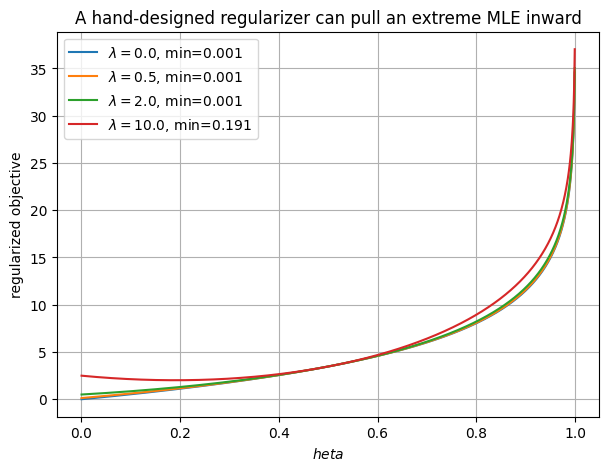

In [ ]:
N1, N0 = 0, 5
theta_star = 0.5

for lam in [0.0, 0.5, 2.0, 10.0]:
    objective = bernoulli_nll(theta_grid, N1, N0) + lam*(theta_grid-theta_star)**2
    theta_hat = theta_grid[np.argmin(objective)]
    plt.plot(theta_grid, objective, label=fr'$\lambda={lam}$, min={theta_hat:.3f}')

plt.xlabel(r'$	heta$')
plt.ylabel('regularized objective')
plt.title('A hand-designed regularizer can pull an extreme MLE inward')
plt.legend()
plt.show()

## 10. Prior distribution

A prior $p(\theta)$ encodes beliefs about plausible parameter values **before seeing the current data**.

For a parameter constrained to $[0,1]$, the **Beta family** is especially natural:

$$
p(\theta)=\operatorname{Beta}(\theta\mid\alpha,\beta)
\propto \theta^{\alpha-1}(1-\theta)^{\beta-1}.
$$

Different hyperparameters express different prior beliefs.

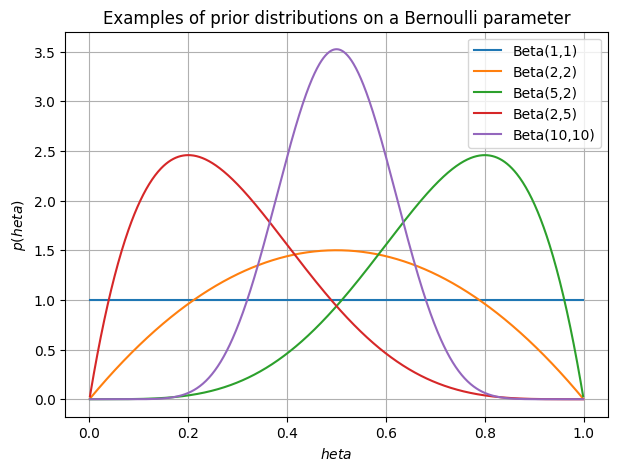

In [ ]:
prior_specs = [(1,1), (2,2), (5,2), (2,5), (10,10)]

for a, b in prior_specs:
    plt.plot(theta_grid, beta.pdf(theta_grid, a, b), label=f'Beta({a},{b})')

plt.xlabel(r'$	heta$')
plt.ylabel(r'$p(	heta)$')
plt.title('Examples of prior distributions on a Bernoulli parameter')
plt.legend()
plt.show()

## 11. From prior to posterior

After observing $\mathcal D$, Bayes' rule gives

$$
p(\theta\mid\mathcal D)
=
\frac{p(\mathcal D\mid\theta)p(\theta)}{p(\mathcal D)}
\propto p(\mathcal D\mid\theta)p(\theta).
$$

The denominator

$$
p(\mathcal D)
=\int p(\mathcal D\mid\theta)p(\theta)\,d\theta
$$

is the **marginal likelihood**. It does not depend on $\theta$.

The posterior is a full distribution over parameter values, so its **spread** can describe uncertainty in a way that a single MLE cannot.

/tmp/ipykernel_563/4011199367.py:10: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  posterior_pdf = unnormalized_post / np.trapz(unnormalized_post, theta_grid)
/tmp/ipykernel_563/4011199367.py:12: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  like_for_plot = like / np.trapz(like, theta_grid)


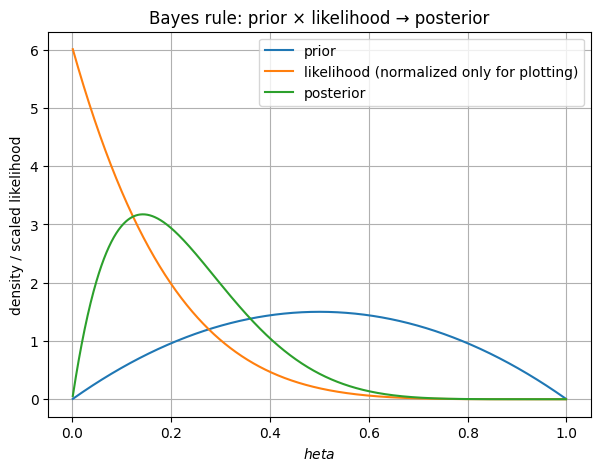

In [ ]:
D_small = np.array([0, 0, 0, 0, 0])
N1 = int(D_small.sum())
N0 = len(D_small) - N1

a, b = 2, 2
prior_pdf = beta.pdf(theta_grid, a, b)
like = theta_grid**N1 * (1-theta_grid)**N0

unnormalized_post = prior_pdf * like
posterior_pdf = unnormalized_post / np.trapz(unnormalized_post, theta_grid)

like_for_plot = like / np.trapz(like, theta_grid)

plt.plot(theta_grid, prior_pdf, label='prior')
plt.plot(theta_grid, like_for_plot, label='likelihood (normalized only for plotting)')
plt.plot(theta_grid, posterior_pdf, label='posterior')
plt.xlabel(r'$	heta$')
plt.ylabel('density / scaled likelihood')
plt.title('Bayes rule: prior × likelihood → posterior')
plt.legend()
plt.show()

## 12. Posterior information and the MAP estimate

The posterior provides more than a point estimate. Its width indicates how concentrated our belief is, and probabilities of parameter ranges can also be computed.

If a single representative value is required, one choice is the **maximum-a-posteriori (MAP)** estimate,

$$
\hat\theta_{\mathrm{MAP}}
=\arg\max_\theta p(\theta\mid\mathcal D).
$$

MAP is the **mode of the posterior**.

In [ ]:
posterior_mode_grid = theta_grid[np.argmax(posterior_pdf)]
posterior_mean_grid = np.trapz(theta_grid * posterior_pdf, theta_grid)

print("Posterior mode (grid approximation):", posterior_mode_grid)
print("Posterior mean  (numerical integration):", posterior_mean_grid)
print("P(theta > 0.25 | D) approximately:",
      np.trapz(posterior_pdf[theta_grid > 0.25], theta_grid[theta_grid > 0.25]))

Posterior mode (grid approximation): 0.14285785785785787
Posterior mean  (numerical integration): 0.2222294146064844
P(theta > 0.25 | D) approximately: 0.3652280375048209


/tmp/ipykernel_563/1101888330.py:2: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  posterior_mean_grid = np.trapz(theta_grid * posterior_pdf, theta_grid)
/tmp/ipykernel_563/1101888330.py:7: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  np.trapz(posterior_pdf[theta_grid > 0.25], theta_grid[theta_grid > 0.25]))


## 13. MAP is a regularized MLE

Using Bayes' rule,

$$
\hat\theta_{\mathrm{MAP}}
=\arg\max_\theta p(\theta\mid\mathcal D)
=\arg\max_\theta
[\log p(\mathcal D\mid\theta)+\log p(\theta)].
$$

Equivalently,

$$
\hat\theta_{\mathrm{MAP}}
=\arg\min_\theta
[\operatorname{NLL}(\mathcal D;\theta)-\log p(\theta)].
$$

Thus $-\log p(\theta)$ acts like a regularizer. MAP is still a **point estimate**, but the prior can pull it away from an extreme likelihood maximum.

## 14. Bernoulli model with a Beta prior: MAP estimate

For the Bernoulli likelihood

$$
p(\mathcal D\mid\theta)=\theta^{N_1}(1-\theta)^{N_0},
$$

and a Beta prior

$$
p(\theta)\propto
\theta^{\alpha-1}(1-\theta)^{\beta-1},
$$

the MAP objective becomes

$$
N_1\log\theta+N_0\log(1-\theta)
+(\alpha-1)\log\theta+(\beta-1)\log(1-\theta).
$$

For the usual interior-mode case,

$$
\boxed{
\hat\theta_{\mathrm{MAP}}
=
\frac{N_1+\alpha-1}
{N+\alpha+\beta-2}
}.
$$

The terms $\alpha-1$ and $\beta-1$ behave like additional counts of ones and zeros: **pseudo-observations**.

In [ ]:
def beta_bernoulli_map(N1, N0, a, b):
    denom = N1 + N0 + a + b - 2
    if denom <= 0:
        return np.nan
    return (N1 + a - 1) / denom

rows = []
for N1, N0 in [(0,5), (1,4), (3,2), (0,5000), (7,3)]:
    mle = N1 / (N1 + N0)
    map_ = beta_bernoulli_map(N1, N0, 2, 2)
    rows.append([N1, N0, mle, map_])

display(pd.DataFrame(
    rows,
    columns=["N1", "N0", "MLE", "MAP with Beta(2,2) prior"]
))

,N1,N0,MLE,"MAP with Beta(2,2) prior"
0,0,5,0.0,0.142857
1,1,4,0.2,0.285714
2,3,2,0.6,0.571429
3,0,5000,0.0,0.000200
4,7,3,0.7,0.666667


## 15. Summary

### What to remember

1. Probabilistic models describe uncertainty using distributions.
2. Binary observations are naturally modeled with a Bernoulli distribution.
3. The true population probability $\theta$ is different from the observed sample fraction $N_1/N$.
4. Likelihood fixes the data and varies the parameter.
5. MLE maximizes likelihood, or equivalently minimizes NLL.
6. For Bernoulli data, $\hat\theta_{\mathrm{MLE}}=N_1/N$.
7. MLE can be overconfident for small samples, and the same MLE can arise from datasets with very different amounts of evidence.
8. A prior $p(\theta)$ encodes beliefs about plausible parameter values before seeing the current data.
9. Bayes' rule combines prior and likelihood to produce the posterior $p(\theta\mid\mathcal D)$.
10. The posterior captures uncertainty, whereas MLE and MAP are point estimates.
11. MAP is equivalent to NLL minimization plus the regularizer $-\log p(\theta)$.
12. With a Beta prior and Bernoulli likelihood, the MAP estimate has a pseudo-observation interpretation.

## Optional exercises

### Exercise 1 — Likelihood shape
Choose several Bernoulli datasets with the same $N$ but different $N_1$. Plot $p(\mathcal D\mid\theta)$ and verify that the maximum occurs at $N_1/N$.

### Exercise 2 — Sample size and MLE
Compare datasets with the same observed fraction but very different sizes. What information does the MLE fail to convey?

### Exercise 3 — Regularization
For $\mathcal D=\{0,0,0,0,0\}$, vary $\lambda$ in a quadratic regularizer $(\theta-0.5)^2$. Track how the minimizer changes.

### Exercise 4 — Prior sensitivity
For the same dataset, plot Beta$(1,1)$, Beta$(2,2)$, and Beta$(10,10)$ priors. How do they change the MAP estimate?

### Exercise 5 — MAP pseudo-observations
Starting from the MAP objective, differentiate it and derive

$$
\hat\theta_{\mathrm{MAP}}
=
\frac{N_1+\alpha-1}{N+\alpha+\beta-2}.
$$